# What does your chatbot forget?
### Comparing chat-memory strategies on LongMemEval, measured without calling an LLM

Every chat agent has a context budget. When the conversation outgrows it, the memory layer decides what stays.
This notebook replays real long conversations from **LongMemEval** through four memory strategies and asks
one measurable question:

> When the user finally asks *"What degree did I graduate with?"*, is the message that contains the answer
> still in the context the model will see?

That's **evidence recall**. It is an upper bound on answer accuracy: a model can't answer from a message it never sees.
It needs no API calls, so the whole study is free, fast and fully reproducible.

| Strategy | What it does |
|---|---|
| **FIFO** | Keep the most recent messages that fit |
| **Flush-to-archive** | The `llama_index` `Memory` policy: when history exceeds 70% of the limit, move the oldest messages out in chunks of `token_flush_size` (default 3000) |
| **Recent + BM25** | Half the budget for recent messages, half for archived messages that match the question (BM25 keyword retrieval) |
| **Recent + random** | Same split, but the archive half is filled at random. This **control** separates "retrieval helps" from "having more budget helps" |

*Data: LongMemEval (Wu et al., 2024, MIT license), dev split via the Kaggle dataset `bonepyaesone/longmemeval-dev-json`.*

In [1]:
import json, sys, random, statistics as st
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

candidates = list(Path("/kaggle/input").glob("**/longmemeval_dev.json")) + [Path("data/longmemeval_dev.json")]
DATA = next(p for p in candidates if p.exists())
questions = json.load(open(DATA, encoding="utf8"))
print(f"{len(questions)} questions; types: {pd.Series([q['question_type'] for q in questions]).value_counts().to_dict()}")

50 questions; types: {'single-session-user': 50}


## 1. The simulator
Everything is in one small, self-contained module: token counting, the four strategies and a BM25 implementation (Kaggle notebooks run offline, so there are no extra packages).

In [2]:
"""Simulate chat-memory strategies on LongMemEval haystacks and measure evidence recall.

A "turn" is one message. Each strategy decides which past turns are in the model's
context when the final question is asked. Recall = the answer-bearing turn is in it.
Token counts use a simple, deterministic approximation (characters / 4) so results
don't depend on a tokenizer download.
"""
from __future__ import annotations

import math
import re
from collections import Counter
from dataclasses import dataclass

TOKEN_RE = re.compile(r"[a-z0-9]+")
STOP = set("""a an the and or but if then of to in on at for with by from as is are was were be been being i you he she it we they me
my your our their this that these those do does did have has had not no so can could would should will just about what which who
how when where why there here up out into over than too very also any some all more most other such only own same s t don""".split())


def ntok(text: str) -> int:
    return max(1, math.ceil(len(text) / 4))


def words(text: str) -> list[str]:
    return [w for w in TOKEN_RE.findall(text.lower()) if w not in STOP]


@dataclass
class Turn:
    idx: int
    role: str
    text: str
    tokens: int
    evidence: bool


def flatten(question: dict) -> list[Turn]:
    out, i = [], 0
    for session in question["haystack_sessions"]:
        for t in session:
            out.append(Turn(i, t["role"], t["content"], ntok(t["content"]), bool(t.get("has_answer"))))
            i += 1
    return out


# ---------------------------------------------------------------- strategies
def fifo(turns: list[Turn], budget: int, **_) -> set[int]:
    """Keep the most recent turns that fit in the budget."""
    kept, used = set(), 0
    for t in reversed(turns):
        if used + t.tokens > budget:
            break
        kept.add(t.idx)
        used += t.tokens
    return kept


def flush_to_archive(turns: list[Turn], budget: int, flush_size: int | None = None, ratio: float = 0.7,
                     trace: list | None = None, **_) -> set[int]:
    """llama_index-style Memory: when the active history exceeds ratio*budget, move
    the oldest messages out until at least `flush_size` tokens were removed. With no
    memory blocks configured, flushed messages are no longer in the context."""
    limit = budget * ratio
    if flush_size is None:
        flush_size = 3000                       # library default
    flush_size = min(flush_size, budget)        # library only lowers it when > token_limit
    active: list[Turn] = []
    used = 0
    for t in turns:
        active.append(t)
        used += t.tokens
        if used > limit:
            removed = 0
            while active and (removed < flush_size or used > limit):
                gone = active.pop(0)
                removed += gone.tokens
                used -= gone.tokens
        if trace is not None:
            trace.append(used)
    return {t.idx for t in active}


class BM25:
    def __init__(self, docs: list[list[str]], k1: float = 1.5, b: float = 0.75):
        self.k1, self.b = k1, b
        self.tf = [Counter(d) for d in docs]
        self.len = [len(d) for d in docs]
        self.avg = sum(self.len) / max(1, len(docs))
        df = Counter(w for d in docs for w in set(d))
        n = len(docs)
        self.idf = {w: math.log(1 + (n - c + 0.5) / (c + 0.5)) for w, c in df.items()}

    def scores(self, query: list[str]) -> list[float]:
        out = []
        for tf, dl in zip(self.tf, self.len):
            s = 0.0
            for w in query:
                f = tf.get(w)
                if f:
                    s += self.idf[w] * f * (self.k1 + 1) / (f + self.k1 * (1 - self.b + self.b * dl / self.avg))
            out.append(s)
        return out


def recent_plus_bm25(turns: list[Turn], budget: int, question: str = "", recent_share: float = 0.5,
                     pair: bool = True, **_) -> set[int]:
    """Keep a FIFO window of recent turns, then fill the rest of the budget with the
    archived turns that best match the question (BM25). With `pair`, a retrieved
    turn brings its neighbour (user<->assistant) so the exchange stays readable."""
    recent = fifo(turns, int(budget * recent_share))
    used = sum(turns[i].tokens for i in recent)
    archive = [t for t in turns if t.idx not in recent]
    if not archive:
        return recent
    bm = BM25([words(t.text) for t in archive])
    ranked = sorted(zip(bm.scores(words(question)), archive), key=lambda x: -x[0])
    kept = set(recent)
    for score, t in ranked:
        if score <= 0:
            break
        group = [t]
        if pair:
            nb = t.idx + 1 if t.role == "user" else t.idx - 1
            if 0 <= nb < len(turns) and nb not in kept:
                group.append(turns[nb])
        cost = sum(g.tokens for g in group if g.idx not in kept)
        if used + cost > budget:
            continue
        for g in group:
            kept.add(g.idx)
        used += cost
    return kept


def evidence_recalled(turns: list[Turn], kept: set[int]) -> bool:
    return any(t.evidence and t.idx in kept for t in turns)


def evidence_age_tokens(turns: list[Turn]) -> int:
    """Tokens between the (latest) evidence turn and the end of the conversation."""
    last = max(t.idx for t in turns if t.evidence)
    return sum(t.tokens for t in turns[last + 1:])


def recent_plus_random(turns: list[Turn], budget: int, recent_share: float = 0.5, seed: int = 0, **_) -> set[int]:
    """Control: same budget split as recent_plus_bm25, but archive turns are chosen at
    random. Separates the effect of *retrieval* from the effect of *having budget*."""
    import random
    rng = random.Random(seed)
    recent = fifo(turns, int(budget * recent_share))
    used = sum(turns[i].tokens for i in recent)
    archive = [t for t in turns if t.idx not in recent]
    rng.shuffle(archive)
    kept = set(recent)
    for t in archive:
        if used + t.tokens <= budget:
            kept.add(t.idx)
            used += t.tokens
    return kept

In [3]:
BLUE, ORANGE, AQUA, YELLOW, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8984"
INK, INK2 = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#d6d5d0",
    "axes.labelcolor": INK2, "text.color": INK, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": "#ebeae6", "grid.linewidth": 0.8, "axes.spines.top": False,
    "axes.spines.right": False, "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10, "figure.dpi": 110,
})
convs = [(q, flatten(q)) for q in questions]
ages = np.array([evidence_age_tokens(t) for _, t in convs])
sizes = np.array([sum(x.tokens for x in t) for _, t in convs])
print(f"Conversation length: median {np.median(sizes)/1000:.0f}k tokens, {np.median([len(t) for _, t in convs]):.0f} messages")
print(f"Answer age (tokens between the answer and the question): median {np.median(ages)/1000:.0f}k, range {ages.min()/1000:.0f}k-{ages.max()/1000:.0f}k")

Conversation length: median 122k tokens, 498 messages
Answer age (tokens between the answer and the question): median 55k, range 1k-114k


## 2. Sanity check before trusting any number

FIFO has an exact closed form: the answer survives **if and only if** the answer message and everything after it fit in
the budget. If the simulator disagrees with that rule even once, nothing else in this notebook can be trusted.

In [4]:
mismatches = 0
for B in [2000, 4000, 8000, 16000, 32000, 64000]:
    for q, t in convs:
        fits = any(sum(y.tokens for y in t[e.idx:]) <= B for e in t if e.evidence)
        mismatches += fits != evidence_recalled(t, fifo(t, B))
print("FIFO vs closed form, mismatches:", mismatches)
assert mismatches == 0

FIFO vs closed form, mismatches: 0


## 3. Evidence recall vs. context budget

In [5]:
BUDGETS = [2000, 4000, 8000, 16000, 32000, 64000]
STRATS = {
    "FIFO": lambda t, B, q: fifo(t, B),
    "Flush-to-archive (default 3000)": lambda t, B, q: flush_to_archive(t, B),
    # Stable per-question seed (Python's hash() is randomised per process, which would make the control irreproducible).
    "Recent + random (control)": lambda t, B, q: recent_plus_random(t, B, seed=sum(map(ord, q))),
    "Recent + BM25": lambda t, B, q: recent_plus_bm25(t, B, question=q),
}
rows = []
for B in BUDGETS:
    for name, fn in STRATS.items():
        for q, t in convs:
            rows.append({"budget": B, "strategy": name, "qid": q["question_id"],
                         "hit": evidence_recalled(t, fn(t, B, q["question"]))})
res = pd.DataFrame(rows)

rng = np.random.default_rng(0)
def boot(x, n=2000):
    x = np.asarray(x, float)
    m = rng.choice(x, size=(n, len(x))).mean(1)
    return x.mean(), *np.percentile(m, [2.5, 97.5])

summary = (res.groupby(["strategy", "budget"]).hit.apply(lambda s: pd.Series(boot(s), index=["recall", "lo", "hi"]))
              .unstack().reset_index())
display(summary.pivot(index="budget", columns="strategy", values="recall").map("{:.0%}".format))

strategy,FIFO,Flush-to-archive (default 3000),Recent + BM25,Recent + random (control)
budget,,,,
2000,4%,2%,86%,4%
4000,4%,4%,94%,6%
8000,8%,4%,98%,16%
16000,16%,8%,100%,10%
32000,36%,26%,100%,28%
64000,58%,44%,100%,58%


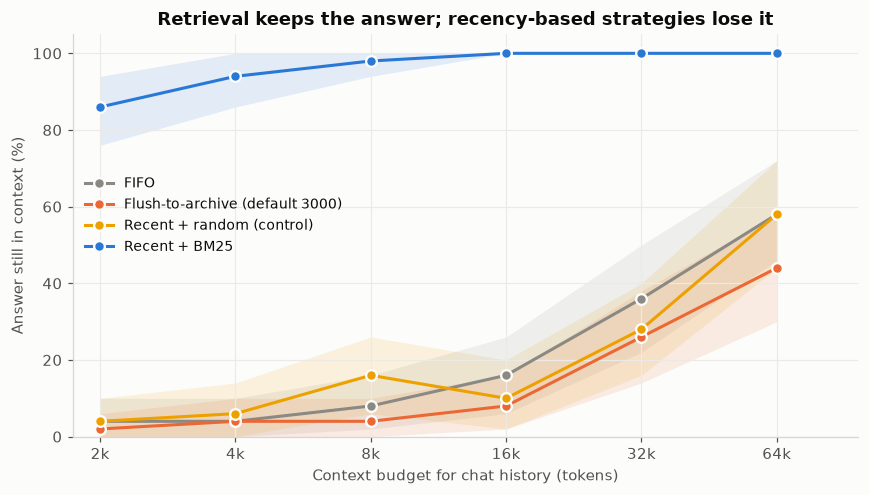

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.6))
colors = {"FIFO": GRAY, "Flush-to-archive (default 3000)": ORANGE, "Recent + random (control)": YELLOW, "Recent + BM25": BLUE}
for name, c in colors.items():
    s = summary[summary.strategy == name].sort_values("budget")
    x = np.arange(len(s))
    ax.fill_between(x, s.lo * 100, s.hi * 100, color=c, alpha=0.12, linewidth=0)
    ax.plot(x, s.recall * 100, color=c, lw=2, marker="o", ms=7, markeredgecolor="#fcfcfb", markeredgewidth=1.5, label=name)
ax.set_xticks(np.arange(len(BUDGETS)), [f"{b//1000}k" for b in BUDGETS])
ax.set_xlabel("Context budget for chat history (tokens)"); ax.set_ylabel("Answer still in context (%)")
ax.set_ylim(0, 105); ax.set_xlim(-0.2, len(BUDGETS) - 0.4)
ax.set_title("Retrieval keeps the answer; recency-based strategies lose it")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(0.0, 0.55), fontsize=9)
plt.tight_layout(); plt.show()

**Reading it:** the median answer is ~55k tokens old, so any recency-based policy needs a budget at least that big.
FIFO only reaches ~58% at 64k. The **random control sits on top of FIFO**, so the jump for BM25 isn't about having
budget to spare: it comes from *choosing* the right old messages. Flush-to-archive does worse than FIFO at the same budget,
because it keeps the history well below the limit, as the next section shows.

## 4. Why flush-to-archive underperforms: the sawtooth (llama_index issue #24117)

`Memory.from_defaults()` flushes 3000 tokens at a time. With `token_limit=3644` (what chat engines use for a 3,900-token
model), the history budget is 0.7 × 3644 ≈ 2,551 tokens, *smaller than one flush*, so every flush empties almost everything.
Below, one conversation is replayed with the default and with a flush size scaled to 10% of the budget.

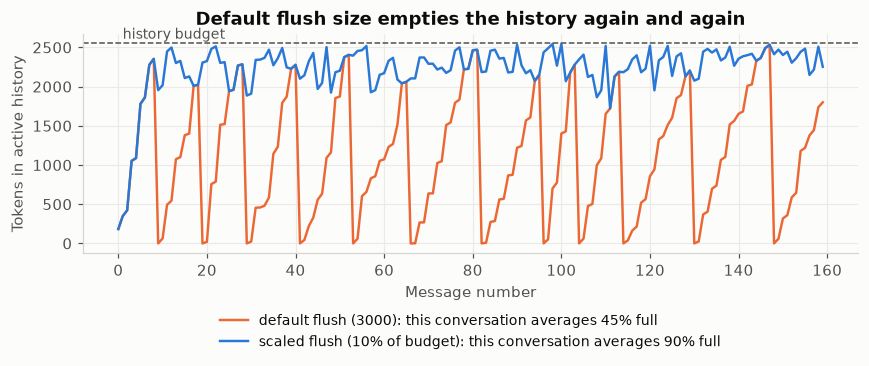

Average fill of the history budget across all 50 conversations: {'default': '46%', 'scaled 10%': '88%'}


In [7]:
q0, t0 = convs[0]
LIMIT = 3644
traces = {}
for label, fs in [("default flush (3000)", None), ("scaled flush (10% of budget)", int(LIMIT * 0.7 * 0.1))]:
    tr = []; flush_to_archive(t0, LIMIT, flush_size=fs, trace=tr); traces[label] = tr

fig, ax = plt.subplots(figsize=(8, 3.6))
for (label, tr), c in zip(traces.items(), [ORANGE, BLUE]):
    ax.plot(tr[:160], color=c, lw=1.6, label=f"{label}: this conversation averages {np.mean(tr[50:])/(LIMIT*0.7):.0%} full")
ax.axhline(LIMIT * 0.7, color=INK2, lw=1, ls="--"); ax.text(1, LIMIT * 0.7 + 60, "history budget", color=INK2, fontsize=9)
ax.set_xlabel("Message number"); ax.set_ylabel("Tokens in active history")
ax.set_title("Default flush size empties the history again and again")
ax.legend(frameon=False, fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=1)
plt.tight_layout(); plt.show()

fill = {}
for lab, fs in [("default", None), ("scaled 10%", int(LIMIT * 0.7 * 0.1))]:
    per_conv = []
    for _, t in convs:
        tr = []
        flush_to_archive(t, LIMIT, flush_size=fs, trace=tr)
        per_conv.append(np.mean(tr[50:]) / (LIMIT * 0.7))  # skip the warm-up before the first flush
    fill[lab] = np.mean(per_conv)
print("Average fill of the history budget across all 50 conversations:", {k: f"{v:.0%}" for k, v in fill.items()})

With the default, the model sees **about half** the history it has room for, on average. A flush size scaled to the
budget keeps it close to full. The fix proposed upstream (scale the default flush size with the budget) is the right shape.

## 5. Which answers survive? Recall by answer age

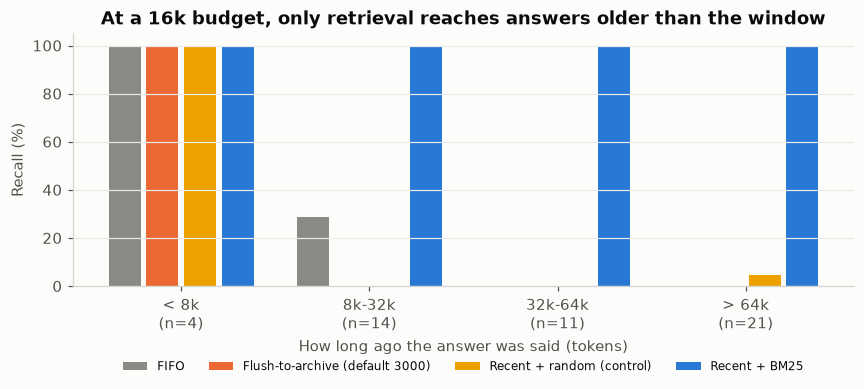

In [8]:
B = 16000
AGE_LABELS = ["< 8k", "8k-32k", "32k-64k", "> 64k"]
age_of = dict(zip([q["question_id"] for q, _ in convs],
                  pd.cut(ages, [-1, 8000, 32000, 64000, 1e9], labels=AGE_LABELS).astype(str)))
age_bins = pd.Categorical([age_of[q["question_id"]] for q, _ in convs], categories=AGE_LABELS, ordered=True)
sub = res[res.budget == B].copy()
sub["age"] = pd.Categorical(sub.qid.map(age_of), categories=AGE_LABELS, ordered=True)
by_age = (sub
            .groupby(["age", "strategy"], observed=True).hit.mean().unstack() * 100)
n_per_bin = pd.Series(age_bins).value_counts().reindex(by_age.index)

fig, ax = plt.subplots(figsize=(8, 3.8))
w = 0.2
for i, (name, c) in enumerate(colors.items()):
    ax.bar(np.arange(len(by_age)) + (i - 1.5) * w, by_age[name], width=w - 0.03, color=c, label=name)
ax.set_xticks(np.arange(len(by_age)), [f"{a}\n(n={n})" for a, n in zip(by_age.index, n_per_bin)])
ax.set_xlabel("How long ago the answer was said (tokens)"); ax.set_ylabel("Recall (%)")
ax.set_title(f"At a {B//1000}k budget, only retrieval reaches answers older than the window")
ax.legend(frameon=False, fontsize=8, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.25)); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

## 6. Ablation: how much of the budget should go to recent messages?

In [9]:
shares = [0.0, 0.25, 0.5, 0.75, 0.9]
abl = pd.DataFrame([{"recent_share": s, "budget": B,
                     "recall": np.mean([evidence_recalled(t, recent_plus_bm25(t, B, question=q["question"], recent_share=s)) for q, t in convs])}
                    for s in shares for B in [2000, 4000, 8000]])
display(abl.pivot(index="recent_share", columns="budget", values="recall").map("{:.0%}".format))

budget,2000,4000,8000
recent_share,,,
0.00,94%,98%,98%
0.25,92%,98%,98%
0.50,86%,94%,98%
0.75,58%,90%,94%
0.90,36%,54%,80%


Recall stays high until most of the budget goes to recent messages. In a real agent the recent window matters for
coherence (pronouns, follow-ups), which this metric doesn't measure. So the split is a product decision,
and this table shows what each choice costs in recall.

## 7. Limitations: please read before quoting the numbers

- **Easy questions for keyword search.** This dev split is all `single-session-user` questions ("What degree did I graduate with?"),
  which share words with the answer message. Paraphrased or multi-hop questions (other LongMemEval types) would favour embedding
  retrieval and lower BM25's numbers. Treat the BM25 curve as **optimistic**.
- **Recall, not accuracy.** Having the answer in context is necessary, not sufficient; models still miss facts buried in long contexts.
- **The question is known at retrieval time.** That's realistic for answering, but not for proactive memory (e.g. summarising
  before anyone asks).
- **Approximate tokens** (characters / 4) and **n = 50 questions**; confidence bands are shown where it matters.

## Takeaways

1. **Recency is not memory.** FIFO and flush policies forget anything older than the window, and that is most answers.
2. **Retrieval over an archive is what makes old facts reachable.** A random-retrieval control with the same budget
   shows the gain comes from retrieval, not from budget.
3. **Small configuration defaults matter:** a flush size larger than the budget leaves the model using about half its context.